# Loan Approval Prediction Using Machine Learning

**Models compared:** Support Vector Machine (SVM), Logistic Regression, and K-Nearest Neighbors (KNN).



## Section 1: Import libraries

In [ ]:
import pandas as pd
import numpy as np
import matplotlib.pyplot as plt
import seaborn as sns

from sklearn.preprocessing import LabelEncoder, StandardScaler
from sklearn.model_selection import train_test_split

from sklearn.svm import SVC
from sklearn.linear_model import LogisticRegression
from sklearn.neighbors import KNeighborsClassifier

from sklearn.metrics import (
    accuracy_score,
    classification_report,
    confusion_matrix,
    precision_score,
    recall_score,
    f1_score
)

## Section 2: Load and explore the dataset

In [ ]:
df = pd.read_csv('/content/loan (1).csv')
df.head()

,loan_id,no_of_dependents,education,self_employed,income_annum,loan_amount,loan_term,cibil_score,residential_assets_value,commercial_assets_value,luxury_assets_value,bank_asset_value,loan_status
0,1,2,Graduate,No,9600000,29900000,12,778,2400000,17600000,22700000,8000000,Approved
1,2,0,Not Graduate,Yes,4100000,12200000,8,417,2700000,2200000,8800000,3300000,Rejected
2,3,3,Graduate,No,9100000,29700000,20,506,7100000,4500000,33300000,12800000,Rejected
3,4,3,Graduate,No,8200000,30700000,8,467,18200000,3300000,23300000,7900000,Rejected
4,5,5,Not Graduate,Yes,9800000,24200000,20,382,12400000,8200000,29400000,5000000,Rejected


In [ ]:
# Check dataset size, column types, and missing values
print('Dataset shape:', df.shape)
print('Column information:')
df.info()
print('\nMissing values in each column:')
print(df.isnull().sum())

Dataset shape: (4269, 13)
Column information:
<class 'pandas.core.frame.DataFrame'>
RangeIndex: 4269 entries, 0 to 4268
Data columns (total 13 columns):
 #   Column                    Non-Null Count  Dtype 
---  ------                    --------------  ----- 
 0   loan_id                   4269 non-null   int64 
 1   no_of_dependents          4269 non-null   int64 
 2   education                 4269 non-null   object
 3   self_employed             4269 non-null   object
 4   income_annum              4269 non-null   int64 
 5   loan_amount               4269 non-null   int64 
 6   loan_term                 4269 non-null   int64 
 7   cibil_score               4269 non-null   int64 
 8   residential_assets_value  4269 non-null   int64 
 9   commercial_assets_value   4269 non-null   int64 
 10  luxury_assets_value       4269 non-null   int64 
 11  bank_asset_value          4269 non-null   int64 
 12  loan_status               4269 non-null   object
dtypes: int64(10), object(3)
memory u

In [ ]:
for col in df.select_dtypes(include=['object']).columns:
    df[col] = df[col].str.strip()

# Remove loan_id because it is an identifier, not a useful prediction feature
if 'loan_id' in df.columns:
    df.drop('loan_id', axis=1, inplace=True)

df.head()

,no_of_dependents,education,self_employed,income_annum,loan_amount,loan_term,cibil_score,residential_assets_value,commercial_assets_value,luxury_assets_value,bank_asset_value,loan_status
0,2,Graduate,No,9600000,29900000,12,778,2400000,17600000,22700000,8000000,Approved
1,0,Not Graduate,Yes,4100000,12200000,8,417,2700000,2200000,8800000,3300000,Rejected
2,3,Graduate,No,9100000,29700000,20,506,7100000,4500000,33300000,12800000,Rejected
3,3,Graduate,No,8200000,30700000,8,467,18200000,3300000,23300000,7900000,Rejected
4,5,Not Graduate,Yes,9800000,24200000,20,382,12400000,8200000,29400000,5000000,Rejected


## Section 3: Data visualization

We use scatter plots to compare loan amount and loan term, a pie chart to view loan-status distribution, and a bar chart to compare model performance.

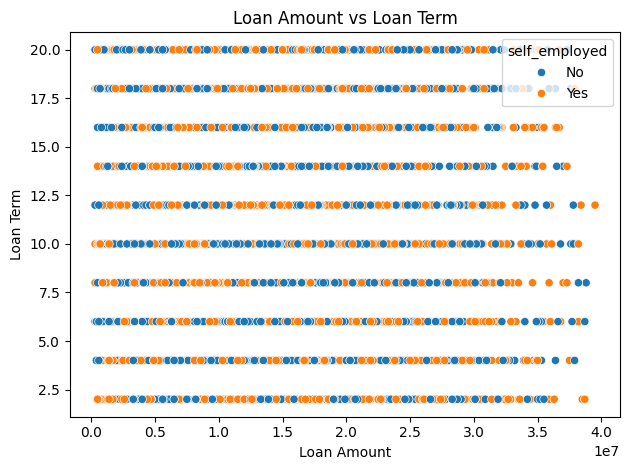

In [ ]:
# Original-style visualization: loan amount vs loan term
sns.scatterplot(
    data=df,
    x='loan_amount',
    y='loan_term',
    hue='self_employed'
)
plt.title('Loan Amount vs Loan Term')
plt.xlabel('Loan Amount')
plt.ylabel('Loan Term')
plt.tight_layout()
plt.show()

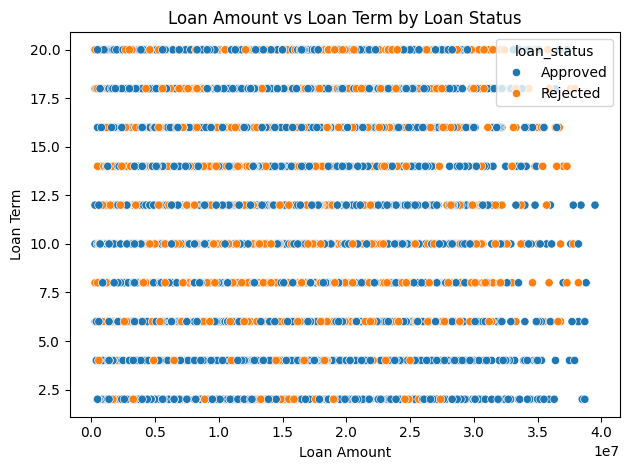

In [ ]:
# Additional visualization: loan amount vs loan term by actual loan status
sns.scatterplot(
    data=df,
    x='loan_amount',
    y='loan_term',
    hue='loan_status'
)
plt.title('Loan Amount vs Loan Term by Loan Status')
plt.xlabel('Loan Amount')
plt.ylabel('Loan Term')
plt.tight_layout()
plt.show()

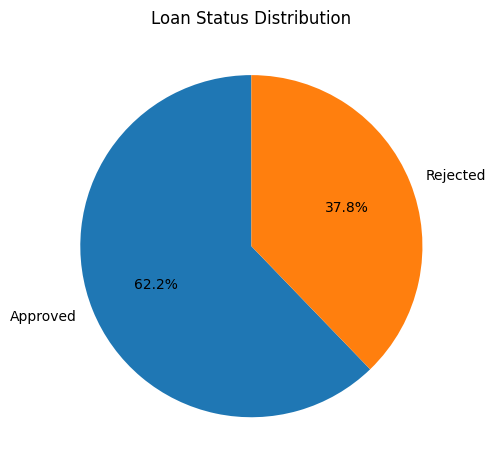

In [ ]:
# Pie chart: distribution of approved and rejected loans
loan_counts = df['loan_status'].value_counts()
loan_counts.plot(kind='pie', autopct='%1.1f%%', startangle=90)
plt.title('Loan Status Distribution')
plt.ylabel('')
plt.tight_layout()
plt.show()

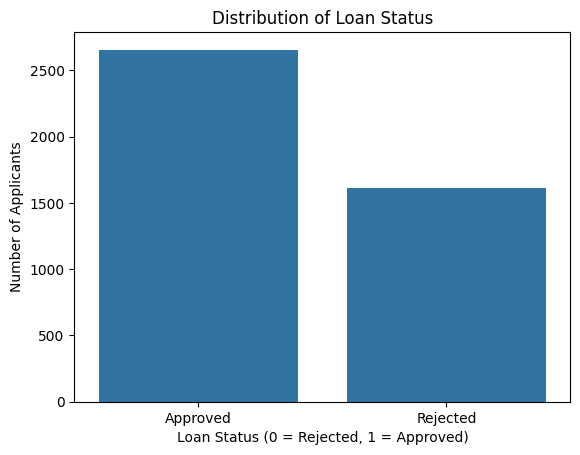

In [ ]:
import seaborn as sns
import matplotlib.pyplot as plt

sns.countplot(data=df, x='loan_status')
plt.title('Distribution of Loan Status')
plt.xlabel('Loan Status (0 = Rejected, 1 = Approved)')
plt.ylabel('Number of Applicants')
plt.show()

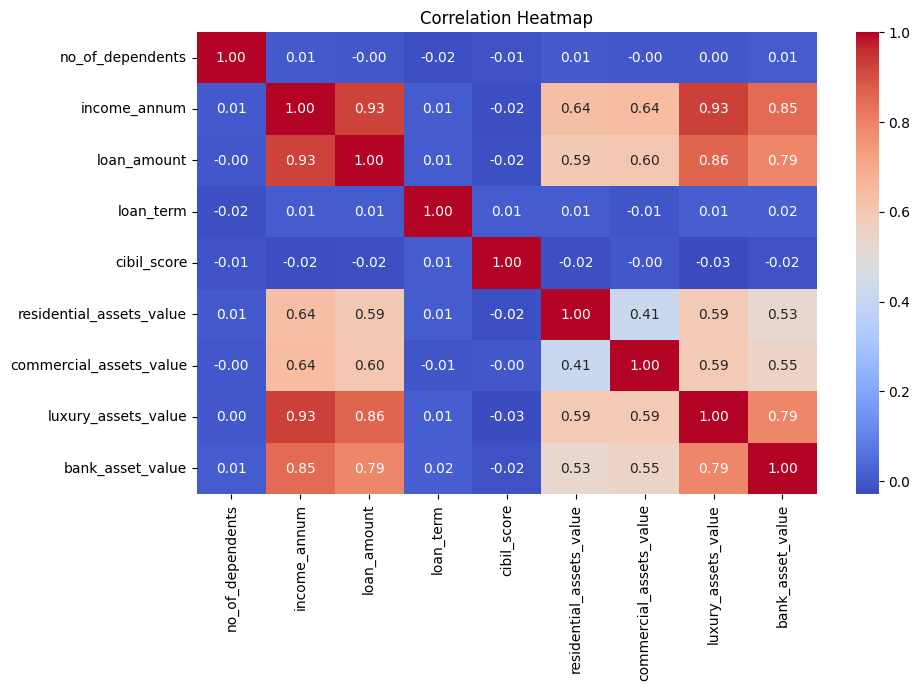

In [ ]:
plt.figure(figsize=(10, 6))

sns.heatmap(
    df.select_dtypes(include=np.number).corr(),
    annot=True,
    cmap='coolwarm',
    fmt='.2f'
)

plt.title('Correlation Heatmap')
plt.show()

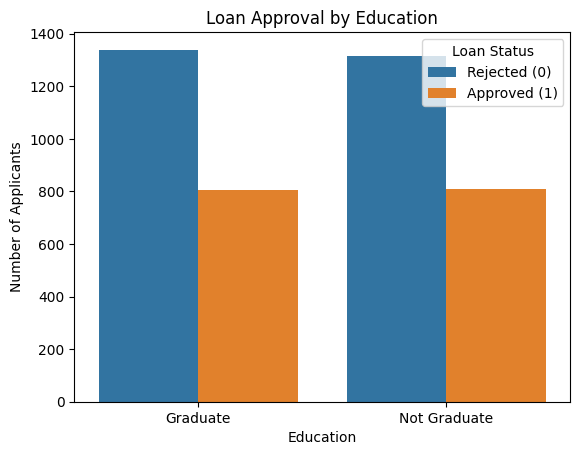

In [ ]:
sns.countplot(
    data=df,
    x='education',
    hue='loan_status'
)

plt.title('Loan Approval by Education')
plt.xlabel('Education')
plt.ylabel('Number of Applicants')
plt.legend(title='Loan Status',
           labels=['Rejected (0)', 'Approved (1)'])
plt.show()

## Section 4: Prepare features and target

`X` contains the input columns, and `Y` contains the loan status we want to predict. Categorical columns are encoded into numeric values because scikit-learn models require numeric inputs. The train-test split is performed **before scaling** to avoid test-data leakage.

In [ ]:
# Separate features (X) and target (Y)
X = df.drop('loan_status', axis=1).copy()
Y = df['loan_status'].copy()

# Handle missing values
for col in X.select_dtypes(include=np.number).columns:
    X[col] = X[col].fillna(X[col].median())

for col in X.select_dtypes(include='object').columns:
    X[col] = X[col].fillna(X[col].mode()[0])

# Apply Label Encoding to categorical features
le = LabelEncoder()

for col in X.select_dtypes(include='object').columns:
    X[col] = le.fit_transform(X[col].astype(str))

# Encode target variable
Y = le.fit_transform(Y.astype(str))

print("Features shape:", X.shape)
print("Target shape:", Y.shape)
print("Preprocessing completed!")

Features shape: (4269, 11)
Target shape: (4269,)
Preprocessing completed!


In [ ]:
# Split first; stratify keeps class proportions similar in train and test sets
X_train, X_test, y_train, y_test = train_test_split(
    X, Y,
    test_size=0.30,
    random_state=42,
    stratify=Y
)

print('Training data shape:', X_train.shape)
print('Testing data shape:', X_test.shape)
# Scale the data (fit scaler on training data only)
scaler = StandardScaler()
X_train = scaler.fit_transform(X_train)
X_test = scaler.transform(X_test)


Training data shape: (2988, 11)
Testing data shape: (1281, 11)


## Section 5: Train and compare three models

We scale the data once above, then train SVM, Logistic Regression, and KNN directly without pipelines.


In [ ]:
models = {
    'SVM': SVC(kernel='rbf'),
    'Logistic Regression': LogisticRegression(max_iter=1000),
    'KNN': KNeighborsClassifier(n_neighbors=5)
}

results = []
trained_models = {}
predictions = {}

for name, model in models.items():
    model.fit(X_train, y_train)
    y_pred = model.predict(X_test)

    trained_models[name] = model
    predictions[name] = y_pred

    results.append({
        'Model': name,
        'Accuracy': accuracy_score(y_test, y_pred),
        'Precision (weighted)': precision_score(
            y_test, y_pred, average='weighted', zero_division=0
        ),
        'Recall (weighted)': recall_score(
            y_test, y_pred, average='weighted', zero_division=0
        ),
        'F1 Score (weighted)': f1_score(
            y_test, y_pred, average='weighted', zero_division=0
        )
    })

    print('\n' + '=' * 55)
    print('Model:', name)
    print(classification_report(
        y_test,
        y_pred,
        labels=np.arange(len(le.classes_)),
        target_names=le.classes_,
        zero_division=0
    ))

results_df = pd.DataFrame(results)
print('\nModel comparison table:')
display(results_df.round(4))


Model: SVM
              precision    recall  f1-score   support

    Approved       0.96      0.96      0.96       797
    Rejected       0.93      0.93      0.93       484

    accuracy                           0.95      1281
   macro avg       0.94      0.94      0.94      1281
weighted avg       0.95      0.95      0.95      1281


Model: Logistic Regression
              precision    recall  f1-score   support

    Approved       0.93      0.95      0.94       797
    Rejected       0.91      0.89      0.90       484

    accuracy                           0.93      1281
   macro avg       0.92      0.92      0.92      1281
weighted avg       0.93      0.93      0.93      1281


Model: KNN
              precision    recall  f1-score   support

    Approved       0.91      0.93      0.92       797
    Rejected       0.87      0.84      0.86       484

    accuracy                           0.89      1281
   macro avg       0.89      0.88      0.89      1281
weighted avg       0.8

,Model,Accuracy,Precision (weighted),Recall (weighted),F1 Score (weighted)
0,SVM,0.9454,0.9454,0.9454,0.9454
1,Logistic Regression,0.9266,0.9264,0.9266,0.9264
2,KNN,0.8938,0.8934,0.8938,0.8934


## Section 6: Compare model performance

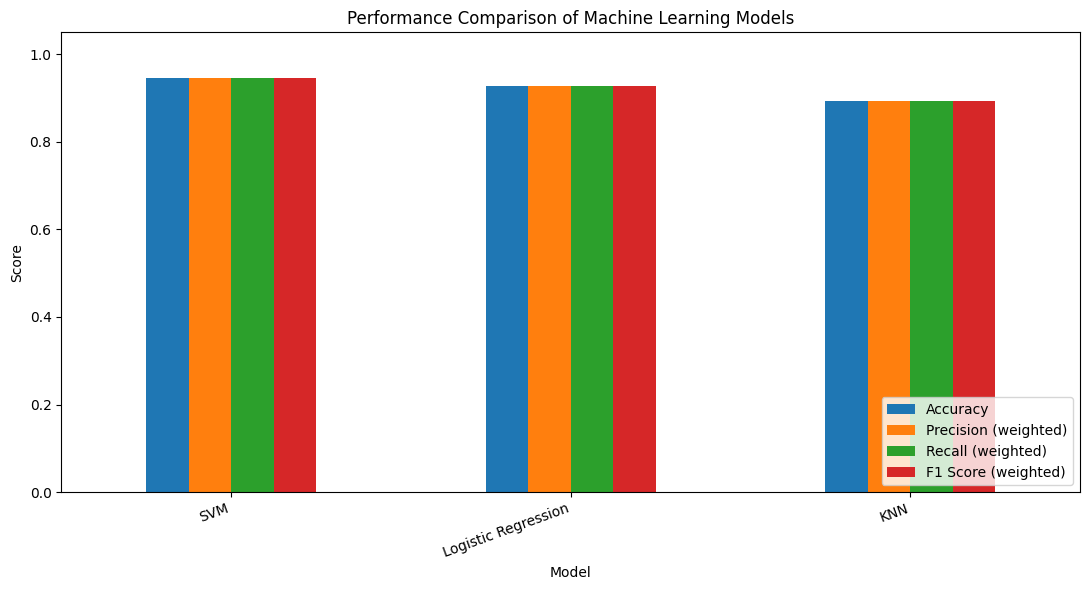

In [ ]:
results_df.set_index('Model')[
    ['Accuracy', 'Precision (weighted)', 'Recall (weighted)', 'F1 Score (weighted)']
].plot(kind='bar', figsize=(11, 6))

plt.title('Performance Comparison of Machine Learning Models')
plt.ylabel('Score')
plt.ylim(0, 1.05)
plt.xticks(rotation=20, ha='right')
plt.legend(loc='lower right')
plt.tight_layout()
plt.show()

## Section 7: Confusion matrix for the best model

Here, the best model is selected by its weighted F1-score on the test set. The confusion matrix shows actual classes against predicted classes.

Best model by weighted F1-score: SVM
Accuracy: 94.54 %


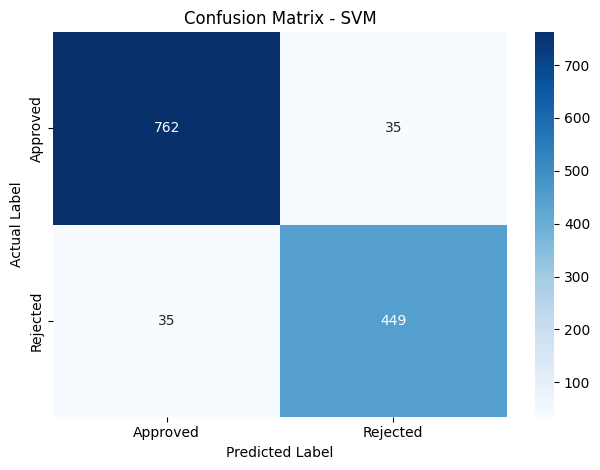

In [ ]:
best_model_name = results_df.loc[
    results_df['F1 Score (weighted)'].idxmax(), 'Model'
]
best_predictions = predictions[best_model_name]

print('Best model by weighted F1-score:', best_model_name)
print('Accuracy:', round(accuracy_score(y_test, best_predictions) * 100, 2), '%')

cm = confusion_matrix(
    y_test,
    best_predictions,
    labels=np.arange(len(le.classes_))
)

sns.heatmap(
    cm,
    annot=True,
    fmt='d',
    cmap='Blues',
    xticklabels=le.classes_,
    yticklabels=le.classes_
)
plt.xlabel('Predicted Label')
plt.ylabel('Actual Label')
plt.title(f'Confusion Matrix - {best_model_name}')
plt.tight_layout()
plt.show()